# Takahashi pCO2 Climatology Processing

## 0. Imports & Setup

In [1]:
import os
import gc
import shutil
import random
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    return True

set_seed(42)

True

In [3]:
# Detect HPC vs local
HOME = os.path.expanduser("~")
HPC_ROOT = os.path.join(HOME, "irp-efs25")
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Use HPC path if it exists, otherwise local
IS_HPC = os.path.exists(HPC_ROOT)
ROOT = HPC_ROOT if IS_HPC else REPO_ROOT

DATA_ROOT = os.path.join(ROOT, "data")
RAW_DATA_DIR = os.path.join(DATA_ROOT, "raw")
PROCESSED_DATA_DIR = os.path.join(DATA_ROOT, "processed")

SATELLITE_LOAD_DIR = os.path.join(PROCESSED_DATA_DIR, "satellite")
TAKAHASHI_LOAD_DIR = os.path.join(RAW_DATA_DIR, "takahashi_climatology")
THERMAL_SAVE_DIR = os.path.join(PROCESSED_DATA_DIR, "takahashi_thermal")

os.makedirs(THERMAL_SAVE_DIR, exist_ok=True)

print(f"Running on {'HPC' if IS_HPC else 'local'}")
print(f"Root: {ROOT}")
print(f"Data root: {DATA_ROOT}")
print(f"Raw data: {RAW_DATA_DIR}")
print(f"Processed data: {PROCESSED_DATA_DIR}")
print(f"Satellite: {SATELLITE_LOAD_DIR}")
print(f"Takahashi Climatology: {TAKAHASHI_LOAD_DIR}")
print(f"Thermal output: {THERMAL_SAVE_DIR}")

Running on HPC
Root: /rds/general/user/efs25/home/irp-efs25
Data root: /rds/general/user/efs25/home/irp-efs25/data
Raw data: /rds/general/user/efs25/home/irp-efs25/data/raw
Processed data: /rds/general/user/efs25/home/irp-efs25/data/processed
Satellite: /rds/general/user/efs25/home/irp-efs25/data/processed/satellite
Takahashi Climatology: /rds/general/user/efs25/home/irp-efs25/data/raw/takahashi_climatology
Thermal output: /rds/general/user/efs25/home/irp-efs25/data/processed/takahashi_thermal


## 1. Load Data

In [4]:
SATELLITE_PATH = os.path.join(SATELLITE_LOAD_DIR, "satellite_covariates_1deg_1970_2024.zarr")
TAKAHASHI_PATH = os.path.join(TAKAHASHI_LOAD_DIR, "data/0-data/TakahashiClimatology_SOCAT_v2023.nc")

assert os.path.exists(SATELLITE_PATH), f"Satellite file not found: {SATELLITE_PATH}"
assert os.path.exists(TAKAHASHI_PATH), f"Takahashi file not found: {TAKAHASHI_PATH}"

ds_sat = xr.open_zarr(SATELLITE_PATH)
ds_tak = xr.open_dataset(TAKAHASHI_PATH, decode_times=True)

print(f"Loaded satellite covariates: {SATELLITE_PATH}")
print(f"Satellite vars: {list(ds_sat.data_vars)}")
print(f"Satellite dims: {dict(ds_sat.sizes)}")
print(f"Satellite time coverage: {str(ds_sat.time.values[0])[:10]} to {str(ds_sat.time.values[-1])[:10]}")

print("\nLoaded takahashi climatology")
print(ds_tak)

print("Takahashi vars:", list(ds_tak.data_vars))
print("Takahashi dims:", ds_tak.dims)
print("Takahashi coords:", list(ds_tak.coords))

print("\nTakahashi variables description:")
for v in ["flux", "dfco2", "atmfco2"]:
    print(v, ds_tak[v].dims, ds_tak[v].shape, ds_tak[v].attrs.get("long_name", ""), ds_tak[v].attrs.get("units", ""))

/rds/general/user/efs25/home/miniconda3/envs/irp-efs25/lib/python3.11/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'kerchunk' loading failed:
No module named 'zarr.core.array_spec'; 'zarr.core' is not a package
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


Loaded satellite covariates: /rds/general/user/efs25/home/irp-efs25/data/processed/satellite/satellite_covariates_1deg_1970_2024.zarr
Satellite vars: ['chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'sos', 'sos_anom', 'tos', 'tos_anom']
Satellite dims: {'time': 660, 'lat': 180, 'lon': 360}
Satellite time coverage: 1970-01-01 to 2024-12-01

Loaded takahashi climatology
<xarray.Dataset> Size: 19MB
Dimensions:  (lon: 360, lat: 180, month: 12)
Coordinates:
  * lon      (lon) float64 3kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * month    (month) float64 96B 1.0 2.0 3.0 4.0 5.0 ... 8.0 9.0 10.0 11.0 12.0
Data variables:
    flux     (lon, lat, month) float64 6MB ...
    dfco2    (lon, lat, month) float64 6MB ...
    atmfco2  (lon, lat, month) float64 6MB ...
Attributes:
    Title:        Takahashi climatology v2023, based on SOCAT data
    Authors:      A Fay and D Munro
    Date:         28 August 2023


## 2. Preprocessing

In [5]:
# check what fixes needed
sat_tos = ds_sat["tos"]
print("Longitude convention check")
for name, da in [("ds_tak (flux)", ds_tak["flux"]), ("sat_tos", sat_tos)]:
    if "lon" in da.coords:
        lon = da["lon"].values
        print(f"{name}: lon min={np.nanmin(lon):.2f}, max={np.nanmax(lon):.2f}, "
              f"convention={'-180 to 180' if np.nanmin(lon)<0 else '0 to 360'}")
    else:
        print(f"{name}: no 'lon' coord found")

print("\nDimension order check")
print("ds_tak['flux'].dims:", ds_tak["flux"].dims)
print("ds_tak['dfco2'].dims:", ds_tak["dfco2"].dims)
print("ds_tak['atmfco2'].dims:", ds_tak["atmfco2"].dims)
print("sat_tos.dims:", sat_tos.dims)

print("\nMonth coverage check (Takahashi climatology)")
if "month" in ds_tak.coords:
    print("ds_tak month values:", ds_tak["month"].values)
    print("ds_tak month dtype:", ds_tak["month"].values.dtype)
else:
    print("No 'month' coord found in ds_tak")

print("\nTime axis check (satellite)")
print("sat_tos time range:", str(sat_tos.time.values[0])[:10], "to", str(sat_tos.time.values[-1])[:10])
print("sat_tos time length:", len(sat_tos.time.values))
print("sat_tos time dtype:", sat_tos.time.values.dtype)

sample_months = np.array([pd.Timestamp(t).month for t in sat_tos.time.values[:15]])
print("First 15 target months extracted:", sample_months)

Longitude convention check
ds_tak (flux): lon min=0.50, max=359.50, convention=0 to 360
sat_tos: lon min=-179.50, max=179.50, convention=-180 to 180

Dimension order check
ds_tak['flux'].dims: ('lon', 'lat', 'month')
ds_tak['dfco2'].dims: ('lon', 'lat', 'month')
ds_tak['atmfco2'].dims: ('lon', 'lat', 'month')
sat_tos.dims: ('time', 'lat', 'lon')

Month coverage check (Takahashi climatology)
ds_tak month values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
ds_tak month dtype: float64

Time axis check (satellite)
sat_tos time range: 1970-01-01 to 2024-12-01
sat_tos time length: 660
sat_tos time dtype: datetime64[ns]
First 15 target months extracted: [ 1  2  3  4  5  6  7  8  9 10 11 12  1  2  3]


### Helper functions

In [6]:
def to_neg180_180(ds, lon_name="lon"):
    lon_new = ((ds[lon_name]+180) % 360) - 180
    ds = ds.assign_coords({lon_name: lon_new})
    return ds.sortby(lon_name)

def transpose_month_lat_lon(da):
    wanted = [d for d in ["month", "lat", "lon"] if d in da.dims]

    return da.transpose(*wanted, missing_dims="ignore")

def transpose_time_lat_lon(da):
    wanted = [d for d in ["time", "lat", "lon"] if d in da.dims]
    
    return da.transpose(*wanted, missing_dims="ignore")

def to_month_index(time_values):
    return np.array([pd.Timestamp(t).month for t in time_values], dtype=np.int16)

def month_to_time(da_monthly, target_time):
    month_idx = to_month_index(target_time)
    missing = sorted(set(month_idx.tolist()) - set(np.asarray(da_monthly["month"].values).astype(int).tolist()))

    if len(missing) > 0:
        raise ValueError(f"Monthly climatology missing months: {missing}")
    
    out = da_monthly.sel(month=xr.DataArray(month_idx, dims="time"))
    out = out.assign_coords(time=("time", target_time))

    return out.transpose("time", "lat", "lon", missing_dims="ignore")

### Prepare takahashi monthly baseline

In [7]:
# re-label takahashi lon to match +-180 satellite
ds_tak = to_neg180_180(ds_tak)

print("tak lon range:", ds_tak.lon.min().item(), ds_tak.lon.max().item())
print("sat lon range:", sat_tos.lon.min().item(), sat_tos.lon.max().item())
assert np.allclose(ds_tak.lon.values, sat_tos.lon.values), "still mismatched :("

# transpose ('lon', 'lat', 'month') to ('month', 'lat', 'lon')
tak_flux = transpose_month_lat_lon(ds_tak["flux"])
tak_dfco2 = transpose_month_lat_lon(ds_tak["dfco2"])
tak_atmfco2 = transpose_month_lat_lon(ds_tak["atmfco2"])

print("Takahashi months covered:", tak_dfco2["month"].values)

# Reconstruct ocean-side monthly climatological pCO2-like baseline
tak_spco2_clim = (tak_atmfco2 + tak_dfco2).rename("spco2_clim")
tak_spco2_clim.attrs["long_name"] = "Takahashi monthly climatological surface ocean pCO2 reconstructed as atmfco2 + dfco2"
tak_spco2_clim.attrs["units"] = "uatm"

tak_spco2_clim = tak_dfco2.rename("dfco2_clim")
tak_spco2_clim.attrs["long_name"] = "Takahashi monthly climatological delta fCO2"
tak_spco2_clim.attrs["units"] = "uatm"

print(tak_spco2_clim)
print("spco2 climatology NaN fraction:", float(np.isnan(tak_spco2_clim.values).mean()))
print("dfco2 climatology NaN fraction:", float(np.isnan(tak_spco2_clim.values).mean()))
print("atmfco2 NaN fraction:", float(np.isnan(tak_atmfco2.values).mean()))

# Takahashi monthly dfCO2 climatology
tak_dfco2_clim = tak_dfco2.rename("dfco2_clim")
tak_dfco2_clim.attrs["long_name"] = "Takahashi monthly climatological delta fCO2"
tak_dfco2_clim.attrs["units"] = "uatm"

print(tak_dfco2_clim)
print("dfco2 climatology NaN fraction:", float(np.isnan(tak_dfco2_clim.values).mean()))
print("atmfco2 NaN fraction:", float(np.isnan(tak_atmfco2.values).mean()))

tak lon range: -179.5 179.5
sat lon range: -179.5 179.5
Takahashi months covered: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]


<xarray.DataArray 'dfco2_clim' (month: 12, lat: 180, lon: 360)> Size: 6MB
[777600 values with dtype=float64]
Coordinates:
  * month    (month) float64 96B 1.0 2.0 3.0 4.0 5.0 ... 8.0 9.0 10.0 11.0 12.0
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes:
    units:      uatm
    long_name:  Takahashi monthly climatological delta fCO2
spco2 climatology NaN fraction: 0.45709876543209876
dfco2 climatology NaN fraction: 0.45709876543209876
atmfco2 NaN fraction: 0.3259889403292181
<xarray.DataArray 'dfco2_clim' (month: 12, lat: 180, lon: 360)> Size: 6MB
[777600 values with dtype=float64]
Coordinates:
  * month    (month) float64 96B 1.0 2.0 3.0 4.0 5.0 ... 8.0 9.0 10.0 11.0 12.0
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes:
    units:      uatm
    l

### Prepare satellite SST

In [8]:
# assert "tos" in ds_sat.data_vars, "Expected satellite SST variable 'tos' after rename."

sat_tos = transpose_time_lat_lon(ds_sat["tos"])

print("Satellite SST shape:", sat_tos.shape)
print("Satellite SST dims:", sat_tos.dims)
print("Satellite SST coverage:", str(sat_tos.time.values[0])[:10], "to", str(sat_tos.time.values[-1])[:10])

Satellite SST shape: (660, 180, 360)
Satellite SST dims: ('time', 'lat', 'lon')
Satellite SST coverage: 1970-01-01 to 2024-12-01


### Build monthly satellite SST

In [9]:
sst_clim_monthly = sat_tos.groupby("time.month").mean("time")
sst_clim_monthly = sst_clim_monthly.rename({"month": "month"})
sst_clim_monthly = transpose_month_lat_lon(sst_clim_monthly)

sst_clim_monthly.attrs["long_name"] = "Monthly SST climatology from satellite SST"
sst_clim_monthly.attrs["units"] = sat_tos.attrs.get("units", "")

print(sst_clim_monthly)
print("SST climatology months:", sst_clim_monthly["month"].values)

<xarray.DataArray 'tos' (month: 12, lat: 180, lon: 360)> Size: 6MB
dask.array<stack, shape=(12, 180, 360), dtype=float64, chunksize=(1, 180, 360), chunktype=numpy.ndarray>
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes:
    long_name:  Monthly SST climatology from satellite SST
    units:      


SST climatology months: [ 1  2  3  4  5  6  7  8  9 10 11 12]


### Interpolate takahashi to satellite grid

In [10]:
tak_spco2_on_sat_grid = tak_spco2_clim.interp(
    lat=sat_tos["lat"],
    lon=sat_tos["lon"],
    method="linear"
)

tak_dfco2_on_sat_grid = tak_dfco2_clim.interp(
    lat=sat_tos["lat"],
    lon=sat_tos["lon"],
    method="linear"
)

tak_atmfco2_on_sat_grid = tak_atmfco2.interp(
    lat=sat_tos["lat"],
    lon=sat_tos["lon"],
    method="linear"
)

tak_flux_on_sat_grid = tak_flux.interp(
    lat=sat_tos["lat"],
    lon=sat_tos["lon"],
    method="linear"
)

print("Interpolated Takahashi spco2 baseline to satellite grid", tak_spco2_on_sat_grid.shape)
print("Interpolated spco2 NaN fraction", float(np.isnan(tak_spco2_on_sat_grid.values).mean()))

print("\nInterpolated Takahashi dfco2 baseline to satellite grid:", tak_dfco2_on_sat_grid.shape)
print("Interpolated dfco2 NaN fraction:", float(np.isnan(tak_dfco2_on_sat_grid.values).mean()))

Interpolated Takahashi spco2 baseline to satellite grid (12, 180, 360)
Interpolated spco2 NaN fraction 0.47367283950617284

Interpolated Takahashi dfco2 baseline to satellite grid: (12, 180, 360)
Interpolated dfco2 NaN fraction: 0.47367283950617284


### Expand monthly climatologies to full 1970-2024 month axis

In [11]:
sat_time = sat_tos.time.values

tak_spco2_clim_time = month_to_time(tak_spco2_on_sat_grid, sat_time)
tak_dfco2_clim_time = month_to_time(tak_dfco2_on_sat_grid, sat_time)
tak_atmfco2_time = month_to_time(tak_atmfco2_on_sat_grid, sat_time)
tak_flux_time = month_to_time(tak_flux_on_sat_grid, sat_time)
sst_clim_time = month_to_time(sst_clim_monthly, sat_time)

print("Expanded Takahashi spco2 climatology shape:", tak_spco2_clim_time.shape)
print("Expanded Takahashi dfco2 climatology shape:", tak_dfco2_clim_time.shape)
print("Expanded SST climatology shape:", sst_clim_time.shape)
print("Final output time coverage:", str(sat_time[0])[:10], "to", str(sat_time[-1])[:10], "n =", len(sat_time))

Expanded Takahashi spco2 climatology shape: (660, 180, 360)
Expanded Takahashi dfco2 climatology shape: (660, 180, 360)
Expanded SST climatology shape: (660, 180, 360)
Final output time coverage: 1970-01-01 to 2024-12-01 n = 660


### Compute thermal component

In [12]:
ALPHA = 0.0423  # same as cmip-bennington

sst_anom = (sat_tos - sst_clim_time).rename("tos_anom_from_clim")
sst_anom.attrs["long_name"] = "Satellite SST anomaly relative to monthly satellite SST climatology"
sst_anom.attrs["units"] = sat_tos.attrs.get("units", "")

# Thermal pCO2 component from reconstructed Takahashi climatological spCO2
pco2_thermal = (tak_spco2_clim_time * np.exp(ALPHA * sst_anom)).rename("pco2thermal")
pco2_thermal.attrs["long_name"] = "Thermal pCO2 component from Takahashi climatology and satellite SST"
pco2_thermal.attrs["units"] = "uatm"
pco2_thermal.attrs["alpha"] = ALPHA
pco2_thermal.attrs["formula"] = "pco2_thermal = spco2_clim(month) * exp(alpha * (tos - tosclim(month)))"

# Optional diagnostics
pco2_thermal_delta = (pco2_thermal - tak_spco2_clim_time).rename("pco2_thermal_delta")
pco2_thermal_delta.attrs["long_name"] = "Thermal pCO2 anomaly relative to Takahashi monthly climatological spCO2"
pco2_thermal_delta.attrs["units"] = "uatm"

print(pco2_thermal)
print("pco2 thermal min", float(np.nanmin(pco2_thermal.values)))
print("pco2 thermal max", float(np.nanmax(pco2_thermal.values)))
print("pco2 thermal NaN fraction", float(np.isnan(pco2_thermal.values).mean()))

# Thermalised Takahashi dfCO2 field
dfco2_thermal = (tak_dfco2_clim_time * np.exp(ALPHA * sst_anom)).rename("dfco2_thermal")
dfco2_thermal.attrs["long_name"] = "Thermally adjusted delta fCO2 from Takahashi climatology and satellite SST"
dfco2_thermal.attrs["units"] = "uatm"
dfco2_thermal.attrs["alpha"] = ALPHA
dfco2_thermal.attrs["formula"] = "dfco2_thermal = dfco2_clim(month) * exp(alpha * (tos - tos_clim(month)))"

# thermal anomaly relative to the monthly climatology itself
dfco2_thermal_delta = (dfco2_thermal - tak_dfco2_clim_time).rename("dfco2_thermal_delta")
dfco2_thermal_delta.attrs["long_name"] = "Thermal delta fCO2 anomaly relative to Takahashi monthly climatology"
dfco2_thermal_delta.attrs["units"] = "uatm"

print(dfco2_thermal)
print("dfco2 thermal min:", float(np.nanmin(dfco2_thermal.values)))
print("dfco2 thermal max:", float(np.nanmax(dfco2_thermal.values)))
print("dfco2 thermal NaN fraction:", float(np.isnan(dfco2_thermal.values).mean()))

<xarray.DataArray 'pco2thermal' (time: 660, lat: 180, lon: 360)> Size: 342MB
dask.array<multiply, shape=(660, 180, 360), dtype=float64, chunksize=(1, 180, 360), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 5kB 1970-01-01 1970-02-01 ... 2024-12-01
    month    (time) float64 5kB 1.0 2.0 3.0 4.0 5.0 ... 8.0 9.0 10.0 11.0 12.0
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes:
    long_name:  Thermal pCO2 component from Takahashi climatology and satelli...
    units:      uatm
    alpha:      0.0423
    formula:    pco2_thermal = spco2_clim(month) * exp(alpha * (tos - tosclim...


pco2 thermal min -260.0143551170484


pco2 thermal max 215.75809726622407


pco2 thermal NaN fraction 0.48095679012345677


<xarray.DataArray 'dfco2_thermal' (time: 660, lat: 180, lon: 360)> Size: 342MB
dask.array<multiply, shape=(660, 180, 360), dtype=float64, chunksize=(1, 180, 360), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 5kB 1970-01-01 1970-02-01 ... 2024-12-01
    month    (time) float64 5kB 1.0 2.0 3.0 4.0 5.0 ... 8.0 9.0 10.0 11.0 12.0
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes:
    long_name:  Thermally adjusted delta fCO2 from Takahashi climatology and ...
    units:      uatm
    alpha:      0.0423
    formula:    dfco2_thermal = dfco2_clim(month) * exp(alpha * (tos - tos_cl...


dfco2 thermal min: -260.0143551170484


dfco2 thermal max: 215.75809726622407


dfco2 thermal NaN fraction: 0.48095679012345677


### Build dataset

In [13]:
thermal_ds = xr.Dataset(
    data_vars={
        "pco2_thermal": pco2_thermal,
        "pco2_thermal_delta": pco2_thermal_delta,
        "spco2_clim": tak_spco2_clim_time,
        "dfco2_clim": tak_dfco2_clim_time,
        "atmfco2_clim": tak_atmfco2_time,
        "flux_clim": tak_flux_time,
        "tos": sat_tos,
        "tos_clim": sst_clim_time,
        "tos_anom_from_clim": sst_anom,
    },
    coords={
        "time": sat_tos.time,
        "lat": sat_tos.lat,
        "lon": sat_tos.lon,
    },
    attrs={
        "title": "Satellite thermal delta-fCO2 component from Takahashi climatology",
        "source_takahashi": TAKAHASHI_PATH,
        "source_satellite": SATELLITE_PATH,
        "reference_year_note": "Takahashi climatology monthly baseline referenced to 2010",
        "time_coverage": f"{str(sat_tos.time.values[0])[:10]} to {str(sat_tos.time.values[-1])[:10]}",
        "alpha": ALPHA,
        "note": "Uses reconstructed spco2_clim = atmfco2 + dfco2 as climatological baseline",
    }
)

## 3. Save output

In [14]:
save_zarr_path = os.path.join(THERMAL_SAVE_DIR, "satellite_pco2_thermal_1deg_1970_2024.zarr")

# just in case instead of overwrite
if os.path.exists(save_zarr_path):
    shutil.rmtree(save_zarr_path)

thermal_ds.to_zarr(save_zarr_path, mode="w")

print(f"Saved zarr: {save_zarr_path}")

Saved zarr: /rds/general/user/efs25/home/irp-efs25/data/processed/takahashi_thermal/satellite_pco2_thermal_1deg_1970_2024.zarr


sanity check

In [15]:
print(thermal_ds)

print("\nMonth counts:")
print(pd.Series(pd.to_datetime(thermal_ds.time.values).month).value_counts().sort_index())

print("\nNaN fractions:")
for v in thermal_ds.data_vars:
    print(v, float(np.isnan(thermal_ds[v].values).mean()))

<xarray.Dataset> Size: 3GB
Dimensions:             (time: 660, lat: 180, lon: 360)
Coordinates:
  * time                (time) datetime64[ns] 5kB 1970-01-01 ... 2024-12-01
    month               (time) int64 5kB dask.array<chunksize=(12,), meta=np.ndarray>
  * lat                 (lat) float64 1kB -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * lon                 (lon) float64 3kB -179.5 -178.5 -177.5 ... 178.5 179.5
Data variables:
    pco2_thermal        (time, lat, lon) float64 342MB dask.array<chunksize=(1, 180, 360), meta=np.ndarray>
    pco2_thermal_delta  (time, lat, lon) float64 342MB dask.array<chunksize=(1, 180, 360), meta=np.ndarray>
    spco2_clim          (time, lat, lon) float64 342MB nan nan nan ... nan nan
    dfco2_clim          (time, lat, lon) float64 342MB nan nan nan ... nan nan
    atmfco2_clim        (time, lat, lon) float64 342MB nan nan ... 398.5 398.5
    flux_clim           (time, lat, lon) float64 342MB nan nan nan ... nan nan
    tos                 (time, lat, 

pco2_thermal 0.48095679012345677


pco2_thermal_delta 0.48095679012345677
spco2_clim 0.47367283950617284
dfco2_clim 0.47367283950617284
atmfco2_clim 0.35511316872427984
flux_clim 0.4804218106995885


tos 0.3512962962962963


tos_clim 0.3512962962962963


tos_anom_from_clim 0.3512962962962963


In [16]:
print("\nNaN fractions:")
for v in thermal_ds.data_vars:
    print(v, float(np.isnan(thermal_ds[v].values).mean()))


NaN fractions:


pco2_thermal 0.48095679012345677


pco2_thermal_delta 0.48095679012345677
spco2_clim 0.47367283950617284
dfco2_clim 0.47367283950617284
atmfco2_clim 0.35511316872427984
flux_clim 0.4804218106995885


tos 0.3512962962962963


tos_clim 0.3512962962962963


tos_anom_from_clim 0.3512962962962963


In [17]:
print(thermal_ds["dfco2_clim"].sizes)
print(thermal_ds["dfco2_clim"].lat.values[:5], thermal_ds["dfco2_clim"].lat.values[-5:])
print(thermal_ds["dfco2_clim"].lon.values[:5], thermal_ds["dfco2_clim"].lon.values[-5:])
print(np.diff(thermal_ds["dfco2_clim"].lat.values).min(), np.diff(thermal_ds["dfco2_clim"].lat.values).max())
print(np.diff(thermal_ds["dfco2_clim"].lon.values).min(), np.diff(thermal_ds["dfco2_clim"].lon.values).max())

Frozen({'time': 660, 'lat': 180, 'lon': 360})
[-89.5 -88.5 -87.5 -86.5 -85.5] [85.5 86.5 87.5 88.5 89.5]
[-179.5 -178.5 -177.5 -176.5 -175.5] [175.5 176.5 177.5 178.5 179.5]
1.0 1.0
1.0 1.0


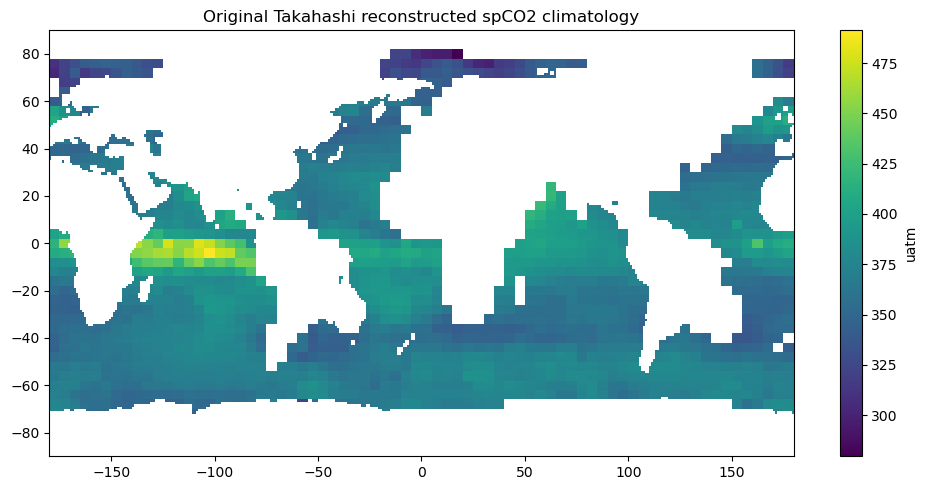

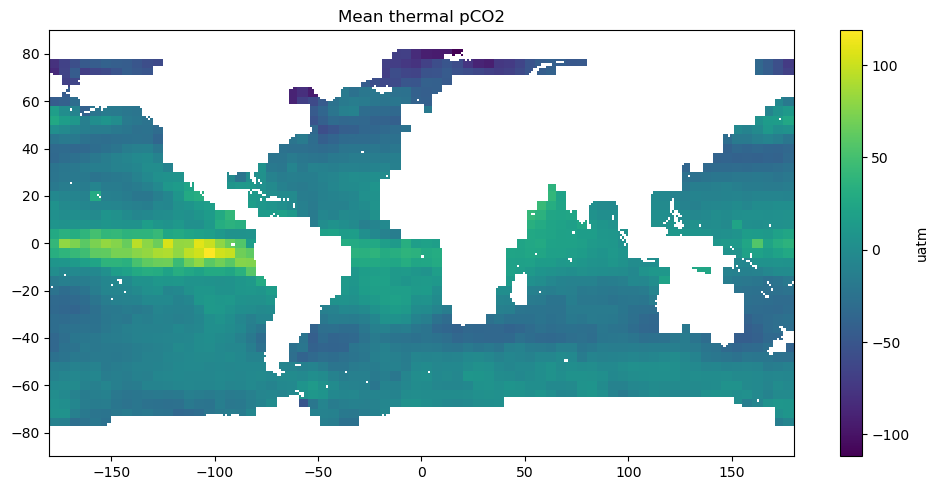

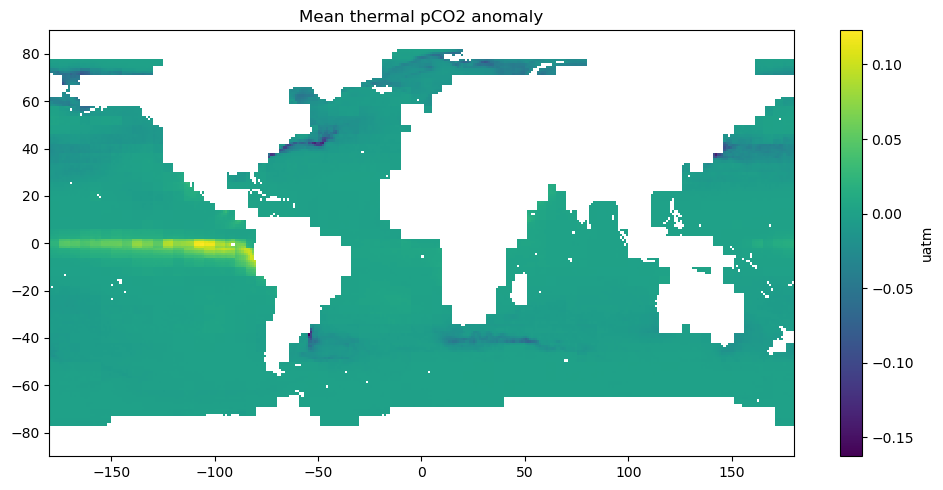

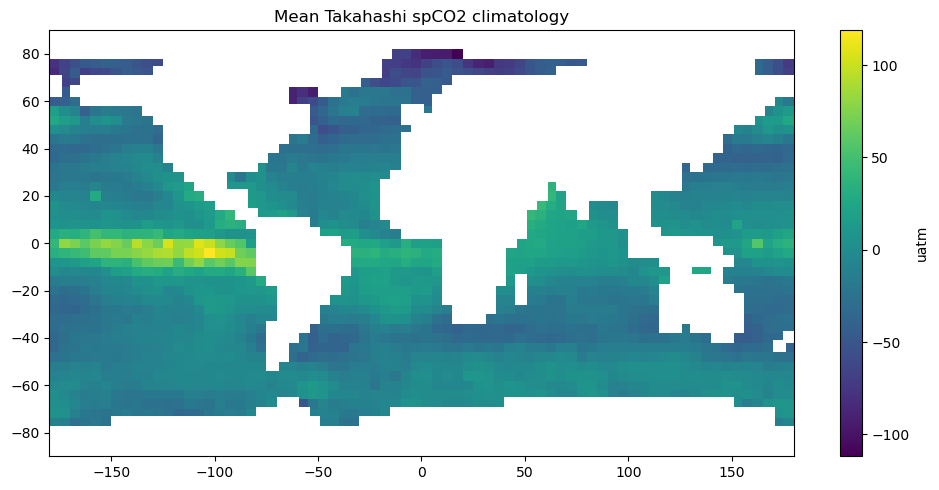

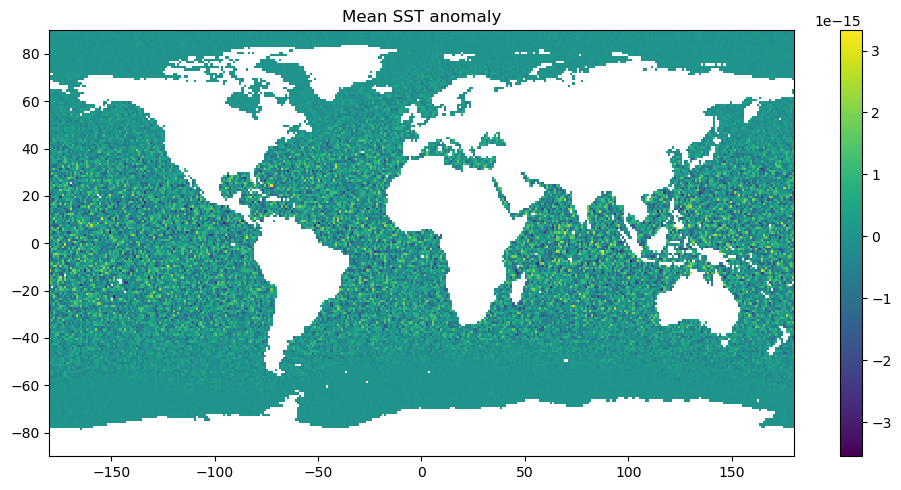

In [18]:
raw_spco2 = (ds_tak["atmfco2"] + ds_tak["dfco2"]).mean("month").transpose("lat", "lon")
thermal_mean = thermal_ds["pco2_thermal"].mean("time")
thermal_delta_mean = thermal_ds["pco2_thermal_delta"].mean("time")
clim_mean = thermal_ds["spco2_clim"].mean("time")
sst_anom_mean = thermal_ds["tos_anom_from_clim"].mean("time")

plt.figure(figsize=(10, 5))
im = plt.pcolormesh(ds_tak.lon, ds_tak.lat, raw_spco2, shading="auto")
plt.colorbar(im, label="uatm")
plt.title("Original Takahashi reconstructed spCO2 climatology")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
im = plt.pcolormesh(thermal_ds.lon, thermal_ds.lat, thermal_mean, shading="auto")
plt.colorbar(im, label="uatm")
plt.title("Mean thermal pCO2")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
im = plt.pcolormesh(thermal_ds.lon, thermal_ds.lat, thermal_delta_mean, shading="auto")
plt.colorbar(im, label="uatm")
plt.title("Mean thermal pCO2 anomaly")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
im = plt.pcolormesh(thermal_ds.lon, thermal_ds.lat, clim_mean, shading="auto")
plt.colorbar(im, label="uatm")
plt.title("Mean Takahashi spCO2 climatology")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
im = plt.pcolormesh(thermal_ds.lon, thermal_ds.lat, sst_anom_mean, shading="auto")
plt.colorbar(im)
plt.title("Mean SST anomaly")
plt.tight_layout()
plt.show()

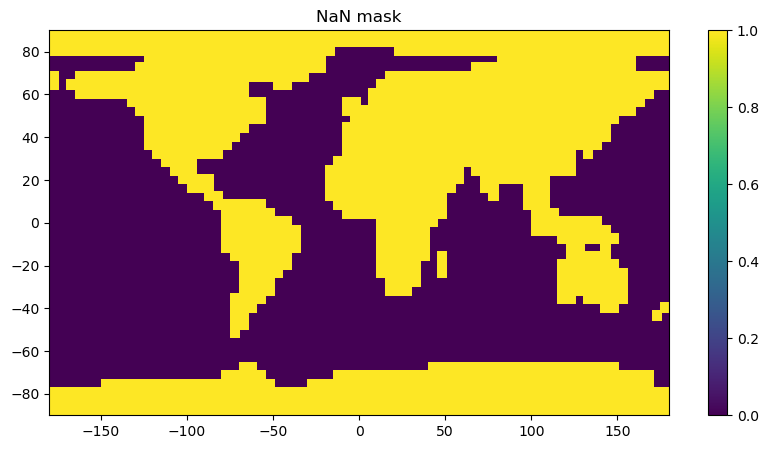

In [19]:
# just to confirm - https://chatgpt.com/share/6a6f90ad-2da0-83eb-ab62-d47a8cdd0072
plt.figure(figsize=(10,5))
plt.pcolormesh(
    thermal_ds.lon,
    thermal_ds.lat,
    np.isnan(clim_mean),
    shading="auto"
)
plt.title("NaN mask")
plt.colorbar()
plt.show()